# POSEIDON: Dual Pipeline IUU Fishing Detection System (WPPNRI 711 - Data 2026)

Pipeline deteksi penangkapan ikan ilegal (*Illegal, Unreported, and Unregulated/IUU Fishing*) di Wilayah Pengelolaan Perikanan Negara Republik Indonesia (WPPNRI 711 - Laut Natuna Utara).

Struktur tahapan:
1. **Phase 1: SAR Data Preparation (Sentinel-1 GFW 2026)**
2. **Phase 2: Earth Engine & Environmental / Radar Feature Extraction**
3. **Phase 3: Spatio-Temporal Tracking & Machine Learning Estimates**
4. Label Engineering

In [ ]:
!pip install pandas numpy matplotlib seaborn tqdm pyarrow gdown geopandas shapely lightgbm xgboost scikit-learn scipy requests earthengine-api pyogrio -q

## Konfigurasi Global, Download Data & Import Library

In [ ]:
import os
import glob
import time
import json
import zipfile
import joblib
import warnings
import requests
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, Polygon, MultiPolygon
from shapely.vectorized import contains as shapely_contains
from scipy.spatial import cKDTree
from scipy.spatial.distance import cdist
from scipy.stats import ks_2samp, chi2_contingency, mannwhitneyu
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, roc_curve, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import xgboost as xgb
import gdown

warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['legend.fontsize'] = 9
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.dpi'] = 120

PALETTE = {
    'old': '#E74C3C',
    'new': '#27AE60',
    'p': '#E74C3C',
    'u': '#95A5A6',
    'rn': '#2E86C1',
    'dark': '#34495E',
    'ais': '#16A085',
    'accent': '#F39C12',
    'purple': '#8E44AD'
}


# Phase 1: SAR Data Preparation (Sentinel-1 GFW & GEE Fallback 2026)

Pengambilan dan penggabungan data citra radar bukaan sintetis (*Synthetic Aperture Radar / SAR*) Sentinel-1:
1. **Data GFW (Januari - Juni 2026)**: Deteksi SAR terstandarisasi Global Fishing Watch.
2. **Data Fallback GEE (Juli - Agustus 2026)**: **Strategi Mitigasi Data Continuity**. Dilakukan pengunduhan citra mentah Sentinel-1 langsung via Google Earth Engine (GEE) yang disaring menggunakan *Isolation Forest* (terlatih pada 150k+ data historis GFW) untuk membersihkan *sea clutter*. Mitigasi ini diterapkan karena pasokan data API GFW mengalami penundaan (*data cut-off*) mulai Juli 2026 akibat transisi satelit, sehingga sistem POSEIDON tetap dapat beroperasi secara penuh dan berkesinambungan.
3. Pemfilteran batas poligon resmi WPPNRI 711 (Badan Informasi Geospasial / BIG), pembersihan duplikasi spasio-temporal, dan standardisasi format waktu.


### Konfigurasi Direktori Data

In [ ]:
FOLDER_BASE = './'
complete_csv_2026 = "POSEIDON_WPP711_complete_2026.csv"
SAR_2026_COMPLETE_ID = "1RzU6ny5wdOOnq8qxcvLfMRlleF4DVoS0"

if not os.path.exists(complete_csv_2026):
    gdown.download(id=SAR_2026_COMPLETE_ID, output=complete_csv_2026, quiet=False)

FALLBACK_2026_ID = "1R4aN2njlbTDh6XG7_xSB4JwOaMtYb16x"
fallback_csv_2026 = "POSEIDON_WPP711_fallback_2026.csv"

if not os.path.exists(fallback_csv_2026):
    gdown.download(id=FALLBACK_2026_ID, output=fallback_csv_2026, quiet=False)

BBOX_LON_MIN, BBOX_LON_MAX = 102.90, 111.05
BBOX_LAT_MIN, BBOX_LAT_MAX = -4.16, 7.74
TAHUN_TARGET = 2026

Downloading...
From: https://drive.google.com/uc?id=1RzU6ny5wdOOnq8qxcvLfMRlleF4DVoS0
To: /content/POSEIDON_WPP711_complete_2026.csv
100%|██████████| 9.12M/9.12M [00:00<00:00, 116MB/s]
Downloading...
From: https://drive.google.com/uc?id=1R4aN2njlbTDh6XG7_xSB4JwOaMtYb16x
To: /content/POSEIDON_WPP711_fallback_2026.csv
100%|██████████| 5.59M/5.59M [00:00<00:00, 28.2MB/s]


### Pemuatan & Penggabungan Berkas Raw SAR 2026 (GFW + Fallback Mitigasi GEE)

Memuat data deteksi kapal GFW (Jan-Jun 2026) dan mengintegrasikannya dengan data hasil mitigasi GEE (Jul-Agu 2026) untuk menghasilkan dataset pantauan SAR tahun 2026 yang utuh tanpa jeda waktu (*zero data gap*).

In [ ]:
list_df_2026 = []

if os.path.exists(complete_csv_2026):
    df_gfw_2026 = pd.read_csv(complete_csv_2026, low_memory=False)
    list_df_2026.append(df_gfw_2026)
    print(f"Data GFW 2026 termuat: {len(df_gfw_2026):,} baris")

if os.path.exists(fallback_csv_2026):
    df_fallback_2026 = pd.read_csv(fallback_csv_2026, low_memory=False)
    list_df_2026.append(df_fallback_2026)
    print(f"Data Mitigasi GEE 2026 termuat: {len(df_fallback_2026):,} baris")

if list_df_2026:
    df_raw_2026 = pd.concat(list_df_2026, ignore_index=True)
    print(f"Total gabungan deteksi SAR 2026: {len(df_raw_2026):,} baris")
else:
    df_raw_2026 = pd.DataFrame()
    print("Tidak ada berkas SAR 2026 yang tersedia.")

Data GFW 2026 termuat: 27,549 baris
Data Mitigasi GEE 2026 termuat: 22,080 baris
Total gabungan deteksi SAR 2026: 49,629 baris


### Penggabungan Dataframe Deteksi SAR 2026

In [ ]:
if not df_raw_2026.empty:
    df_raw_2026['timestamp'] = pd.to_datetime(df_raw_2026['timestamp'], utc=True)
    df_raw_2026['pass_date'] = df_raw_2026['timestamp'].dt.date
    df_raw_2026['quarter'] = df_raw_2026['timestamp'].dt.quarter
    print(f"Dataframe terstandarisasi: {len(df_raw_2026):,} baris")

Dataframe terstandarisasi: 49,629 baris


### Pemfilteran Batas WPP 711 & Pembersihan Data

In [ ]:
if not df_raw_2026.empty:
    os.environ["OGR_GEOJSON_MAX_OBJ_SIZE"] = "0"
    WPP711_GEOJSON_PATH = "wpp711_big_resmi.geojson"

    BIG_URL = "https://kspservices.big.go.id/satupeta/rest/services/PUBLIK/SUMBER_DAYA_ALAM_DAN_LINGKUNGAN/MapServer/21/query"
    BIG_HEADERS = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"}
    BIG_PARAMS = {"where": "namobj = 'WPP-RI 711'", "outFields": "*", "f": "geojson"}

    if not os.path.exists(WPP711_GEOJSON_PATH):
        print("Mengunduh batas WPP 711 resmi dari BIG...")
        response = requests.get(BIG_URL, params=BIG_PARAMS, headers=BIG_HEADERS, timeout=90)
        response.raise_for_status()
        with open(WPP711_GEOJSON_PATH, "w") as f:
            f.write(response.text)
    else:
        print(f"File GeoJSON sudah ada: {WPP711_GEOJSON_PATH}, skip download.")

    wpp_711_only = gpd.read_file(WPP711_GEOJSON_PATH, engine="pyogrio")
    if wpp_711_only.crs is None:
        wpp_711_only = wpp_711_only.set_crs("EPSG:4326", allow_override=True)

    wpp711_geom = wpp_711_only.geometry.union_all()
    minx, miny, maxx, maxy = wpp711_geom.bounds

    print(f'\nBounding box WPP-711 resmi (BIG): lat [{miny:.4f}, {maxy:.4f}], lon [{minx:.4f}, {maxx:.4f}]')
    print(f'Bounding box tabel oseanografi  : lat [-4.16, 7.74], lon [102.9, 111.05]')
    print(f'--> Bandingkan dua baris di atas untuk cek kecocokan cakupan.\n')

    mask_box = (
        (df_raw_2026['lat'] >= miny) & (df_raw_2026['lat'] <= maxy) &
        (df_raw_2026['lon'] >= minx) & (df_raw_2026['lon'] <= maxx)
    )
    df_box_2026 = df_raw_2026[mask_box].copy()

    if len(df_box_2026) > 0:
        mask_poly = shapely_contains(wpp711_geom, df_box_2026['lon'].values, df_box_2026['lat'].values)
        df_natuna_2026 = df_box_2026[mask_poly].copy()
    else:
        df_natuna_2026 = df_box_2026

    df_natuna_2026['timestamp'] = pd.to_datetime(df_natuna_2026['timestamp'], errors='coerce')
    df_natuna_2026['year'] = df_natuna_2026['timestamp'].dt.year
    df_natuna_2026['month'] = df_natuna_2026['timestamp'].dt.month
    df_natuna_2026['hour_utc'] = df_natuna_2026['timestamp'].dt.hour
    df_natuna_2026['day_of_week'] = df_natuna_2026['timestamp'].dt.dayofweek

    df_natuna_2026['season'] = df_natuna_2026['month'].map({
        1: 1, 2: 1, 3: 1, 4: 2, 5: 2, 6: 2,
        7: 3, 8: 3, 9: 3, 10: 4, 11: 4, 12: 4
    })

    df_natuna_2026['ais_matched'] = (
        df_natuna_2026['matched_category'].fillna('unmatched') != 'unmatched'
    ).astype(int)

    for col in ['lat', 'lon', 'presence_score', 'fishing_score', 'length_m', 'matching_score']:
        if col in df_natuna_2026.columns:
            df_natuna_2026[col] = pd.to_numeric(df_natuna_2026[col], errors='coerce')

    sebelum = len(df_natuna_2026)
    if 'presence_score' in df_natuna_2026.columns:
        df_natuna_2026 = df_natuna_2026[df_natuna_2026['presence_score'] >= 0.7].copy()
    sesudah = len(df_natuna_2026)

    df_natuna_2026 = df_natuna_2026.drop_duplicates(subset=['scene_id', 'lat', 'lon']).copy()
    setelah_dedup = len(df_natuna_2026)

    df_natuna_2026 = df_natuna_2026.reset_index(drop=True)
    df_natuna_2026['pass_date'] = df_natuna_2026['timestamp'].dt.floor('D')
    df_natuna_2026['quarter'] = df_natuna_2026['timestamp'].dt.quarter

    print(f'Sebelum filter presence_score < 0.7 : {sebelum:,} baris')
    print(f'Setelah filter                      : {sesudah:,} baris')
    print(f'Setelah drop duplikat               : {setelah_dedup:,} baris')
    print(f'\nRentang tanggal final: {df_natuna_2026["timestamp"].min()} s.d. {df_natuna_2026["timestamp"].max()}')

    print(f"Total deteksi SAR 2026 setelah filter WPP 711 & pembersihan: {len(df_natuna_2026):,} baris")
else:
    df_natuna_2026 = pd.DataFrame()

Mengunduh batas WPP 711 resmi dari BIG...

Bounding box WPP-711 resmi (BIG): lat [-4.1607, 7.7430], lon [102.9012, 111.0547]
Bounding box tabel oseanografi  : lat [-4.16, 7.74], lon [102.9, 111.05]
--> Bandingkan dua baris di atas untuk cek kecocokan cakupan.

Sebelum filter presence_score < 0.7 : 32,897 baris
Setelah filter                      : 32,897 baris
Setelah drop duplikat               : 32,897 baris

Rentang tanggal final: 2026-01-01 11:08:06+00:00 s.d. 2026-08-22 11:24:44+00:00
Total deteksi SAR 2026 setelah filter WPP 711 & pembersihan: 32,897 baris


In [ ]:
df_scenes_wpp = df_natuna_2026[['scene_id', 'timestamp']].drop_duplicates().copy()
df_scenes_wpp['date'] = pd.to_datetime(df_scenes_wpp['timestamp']).dt.date
df_scenes_wpp['month'] = pd.to_datetime(df_scenes_wpp['timestamp']).dt.to_period('M')

scenes_per_day = df_scenes_wpp.groupby('date')['scene_id'].nunique()
scenes_per_month = df_scenes_wpp.groupby('month')['scene_id'].nunique()

total_scene = df_scenes_wpp['scene_id'].nunique()
total_hari_lintasan = len(scenes_per_day)

tgl_awal = df_scenes_wpp['date'].min()
tgl_akhir = df_scenes_wpp['date'].max()
total_hari_kalender = (tgl_akhir - tgl_awal).days + 1

rata_per_hari_aktif = scenes_per_day.mean()
rata_per_hari_kalender = total_scene / total_hari_kalender

print("STATISTIK SCENE SENTINEL-1 TAHUN 2026 (TERFILTER WPP-711)")
print(f"Rentang Tanggal Pengamatan     : {tgl_awal} s.d. {tgl_akhir}")
print(f"Total Deteksi Kapal di WPP-711 : {len(df_natuna_2026):,} deteksi")
print(f"Total Scene Unik di WPP-711    : {total_scene} scene")
print(f"Total Hari Ada Lintasan Satelit: {total_hari_lintasan} hari")
print(f"Total Hari Kalender            : {total_hari_kalender} hari")
print(f"Rata-rata Scene / Hari Lintasan: {rata_per_hari_aktif:.2f} scene/hari")
print(f"Rata-rata Scene / Hari Kalender: {rata_per_hari_kalender:.2f} scene/hari")
print(f"Rentang Scene Harian           : Min {scenes_per_day.min()} | Max {scenes_per_day.max()} scene")
print(f"Median Scene per Hari          : {scenes_per_day.median():.1f} scene")
print("\nRingkasan Scene Unik per Bulan (2026):")
print(scenes_per_month.to_string())
print("\nDistribusi 15 Hari Lintasan Terakhir:")
print(scenes_per_day.tail(15).to_string())

STATISTIK SCENE SENTINEL-1 TAHUN 2026 (TERFILTER WPP-711)
Rentang Tanggal Pengamatan     : 2026-01-01 s.d. 2026-08-22
Total Deteksi Kapal di WPP-711 : 32,897 deteksi
Total Scene Unik di WPP-711    : 462 scene
Total Hari Ada Lintasan Satelit: 129 hari
Total Hari Kalender            : 234 hari
Rata-rata Scene / Hari Lintasan: 3.58 scene/hari
Rata-rata Scene / Hari Kalender: 1.97 scene/hari
Rentang Scene Harian           : Min 1 | Max 7 scene
Median Scene per Hari          : 3.0 scene

Ringkasan Scene Unik per Bulan (2026):
month
2026-01    72
2026-02    55
2026-03    70
2026-04    71
2026-05    48
2026-06    54
2026-07    54
2026-08    38
Freq: M

Distribusi 15 Hari Lintasan Terakhir:
date
2026-07-24    7
2026-07-27    4
2026-07-29    1
2026-07-31    1
2026-08-05    7
2026-08-06    5
2026-08-08    3
2026-08-10    1
2026-08-11    3
2026-08-12    1
2026-08-15    1
2026-08-17    7
2026-08-18    5
2026-08-20    4
2026-08-22    1


### Visualisasi Sebaran Spasial Deteksi SAR Sentinel-1 Tahun 2026

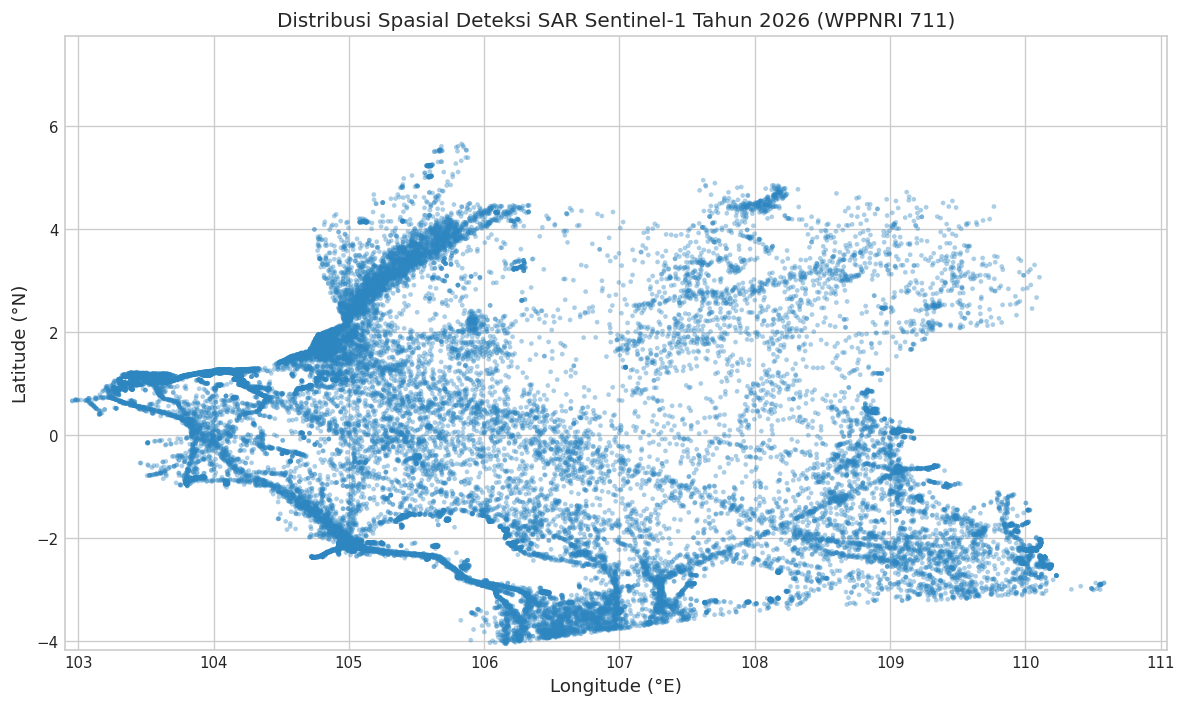

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(df_natuna_2026['lon'], df_natuna_2026['lat'], c=PALETTE['rn'], alpha=0.4, s=8, edgecolors='none')
ax.set_xlim(BBOX_LON_MIN, BBOX_LON_MAX)
ax.set_ylim(BBOX_LAT_MIN, BBOX_LAT_MAX)
ax.set_xlabel('Longitude (°E)')
ax.set_ylabel('Latitude (°N)')
ax.set_title('Distribusi Spasial Deteksi SAR Sentinel-1 Tahun 2026 (WPPNRI 711)')
plt.tight_layout()
plt.show()

# Phase 2: Earth Engine & Environmental / Radar Feature Extraction

Ekstraksi nilai intensitas polarimetri radar (VV dan VH), rasio polarisasi ($VV/VH$), estimasi derau latar (*background clutter*), *signal-to-noise ratio* (SNR dB), jarak ke kawasan konservasi (MPA), batas ZEE Indonesia, pelabuhan terdekat, serta pencocokan ke sinyal AIS untuk mengidentifikasi kapal tanpa transponder (*dark vessels*).

In [ ]:
VESSEL_BUFFER_M = 400
BG_INNER_M      = 200
BG_OUTER_M      = 800
SLEEP_BETWEEN_SCENES = 0.5
SLEEP_PER_100_SCENES = 8.0
SAVE_EVERY_N_SCENES  = 50

### Ekstraksi Fitur Polarimetri Radar (VV, VH, Clutter, SNR)

In [ ]:
def compute_polarimetry_features(df):
    df_out = df.copy()

    if 'vv_intensity_db' in df_out.columns and 'vh_intensity_db' in df_out.columns:
        df_out['radar_intensity_diff'] = (df_out['vv_intensity_db'] - df_out['vh_intensity_db']).astype(np.float32)
        df_out['vv_vh_ratio'] = (df_out['vv_intensity_db'] - df_out['vh_intensity_db']).astype(np.float32)
        if 'background_clutter' in df_out.columns:
            df_out['snr_db'] = (df_out['vv_intensity_db'] - df_out['background_clutter']).astype(np.float32)

    if 'ais_matched' not in df_out.columns:
        if 'matched_category' in df_out.columns:
            df_out['ais_matched'] = (df_out['matched_category'].fillna('unmatched') != 'unmatched').astype(int)
        else:
            df_out['ais_matched'] = 0

    df_out['is_dark'] = (1 - df_out['ais_matched']).astype(int)

    MID_TO_COUNTRY = {
        '525': 'ID', '510': 'ID', '574': 'VN',
        '412': 'CN', '413': 'CN', '414': 'CN', '477': 'HK',
        '338': 'MY', '563': 'SG', '564': 'SG',
        '567': 'TH', '572': 'PH',
        '518': 'MH', '538': 'MH',
        '511': 'PA', '370': 'PA', '371': 'PA', '372': 'PA',
        '636': 'LR', '229': 'MT', '431': 'JP', '440': 'KR', '441': 'KR',
    }
    FLAG_ENCODING = {
        'ID': 0, 'VN': 1, 'CN': 2, 'HK': 3, 'MY': 4, 'SG': 5, 'TH': 6, 'PH': 7,
        'MH': 8, 'PA': 9, 'LR': 10, 'MT': 11, 'JP': 12, 'KR': 13, 'OTHER': 14, 'UNKNOWN': 15,
    }

    if 'mmsi' in df_out.columns:
        def mmsi_to_flag(mmsi):
            if pd.isna(mmsi):
                return 'UNKNOWN'
            try:
                mid = str(int(mmsi))[:3]
                return MID_TO_COUNTRY.get(mid, 'OTHER')
            except Exception:
                return 'UNKNOWN'
        df_out['ais_flag_country'] = df_out['mmsi'].apply(mmsi_to_flag)
        df_out.loc[df_out['ais_matched'] == 0, 'ais_flag_country'] = 'UNKNOWN'
        df_out['ais_flag_country_encoded'] = df_out['ais_flag_country'].map(FLAG_ENCODING).fillna(14).astype(int)
    else:
        df_out['ais_flag_country_encoded'] = 15

    return df_out

df_natuna_2026 = compute_polarimetry_features(df_natuna_2026)
print(f"Fitur polarimetri radar berhasil dikomputasi untuk {len(df_natuna_2026):,} deteksi 2026.")

Fitur polarimetri radar berhasil dikomputasi untuk 32,897 deteksi 2026.


### Pemuatan Berkas Shapefile dan Titik Pelabuhan WPP 711

In [ ]:
import os, zipfile, gdown

file_id = "1Hi05v9z0o397NGZer0YxcEwISpNzrne9"
zip_file = "POSEIDON_WPP711_complete.zip"

if not os.path.exists(zip_file):
    gdown.download(id=file_id, output=zip_file, quiet=False)

if os.path.exists(zip_file):
    with zipfile.ZipFile(zip_file, 'r') as zip_ref:
        zip_ref.extractall('.')
    print("Ekstraksi selesai")

ports_path = "ports/fishing_ports_wpp711.csv"
mpa_path = "shapefiles/mpa_wpp711.shp"
eez_path = "shapefiles/zee_wpp711.shp"

for p in [ports_path, mpa_path, eez_path]:
    print(f"File '{p}': {'Ditemukan' if os.path.exists(p) else 'TIDAK DITEMUKAN'}")

Downloading...
From (original): https://drive.google.com/uc?id=1Hi05v9z0o397NGZer0YxcEwISpNzrne9
From (redirected): https://drive.google.com/uc?id=1Hi05v9z0o397NGZer0YxcEwISpNzrne9&confirm=t&uuid=25feb841-7ce1-44f7-a25f-205406387e28
To: /content/POSEIDON_WPP711_complete.zip
100%|██████████| 29.1M/29.1M [00:00<00:00, 46.9MB/s]


Ekstraksi selesai
File 'ports/fishing_ports_wpp711.csv': Ditemukan
File 'shapefiles/mpa_wpp711.shp': Ditemukan
File 'shapefiles/zee_wpp711.shp': Ditemukan


### Ekstraksi Fitur Proksimitas Geografis Berbasis GIS (MPA, EEZ, Port)

In [ ]:
import geopandas as gpd
from shapely.geometry import Point, Polygon, MultiPolygon
from scipy.spatial import cKDTree

def fill_holes(geom):
    if geom.geom_type == 'Polygon':
        return Polygon(geom.exterior)
    elif geom.geom_type == 'MultiPolygon':
        return MultiPolygon([Polygon(p.exterior) for p in geom.geoms])
    return geom

def haversine_km_vectorized(lat1, lon1, lat2_arr, lon2_arr):
    R = 6371.0
    lat1_r, lon1_r = np.radians(lat1), np.radians(lon1)
    lat2_r, lon2_r = np.radians(lat2_arr), np.radians(lon2_arr)
    dlat = lat2_r - lat1_r
    dlon = lon2_r - lon1_r
    a = np.sin(dlat/2.0)**2 + np.cos(lat1_r)*np.cos(lat2_r)*np.sin(dlon/2.0)**2
    return R * 2.0 * np.arctan2(np.sqrt(a), np.sqrt(1.0-a))

df_ports = pd.read_csv(ports_path)
mpa = gpd.read_file(mpa_path).to_crs('EPSG:4326')
eez = gpd.read_file(eez_path).to_crs('EPSG:4326')
eez['geometry'] = eez.geometry.apply(fill_holes)

ports_lat, ports_lon = df_ports['lat'].values, df_ports['lon'].values

mpa_proj = mpa.to_crs('EPSG:3857')
eez_proj = eez.to_crs('EPSG:3857')
mpa_centroid_coords = np.array([(c.x, c.y) for c in mpa_proj.geometry.centroid])
mpa_tree = cKDTree(mpa_centroid_coords)

gdf_points = gpd.GeoDataFrame(
    df_natuna_2026,
    geometry=gpd.points_from_xy(df_natuna_2026['lon'], df_natuna_2026['lat']),
    crs='EPSG:4326'
)
gdf_points_proj = gdf_points.to_crs('EPSG:3857')

dist_mpa_list, inside_mpa_list, dist_eez_list, dist_port_list = [], [], [], []

for idx, row in gdf_points_proj.iterrows():
    lat, lon = float(row['lat']), float(row['lon'])
    point_geom = row['geometry']
    point_xy = np.array([point_geom.x, point_geom.y])

    _, closest_indices = mpa_tree.query(point_xy, k=min(5, len(mpa_centroid_coords)))
    if isinstance(closest_indices, np.integer):
        closest_indices = [closest_indices]
    candidates = mpa_proj.iloc[closest_indices]

    distances_mpa_m = candidates.boundary.distance(point_geom)
    min_dist_mpa_m = distances_mpa_m.min()
    inside_mpa = int(candidates.contains(point_geom).any())
    d_mpa = -min_dist_mpa_m/1000.0 if inside_mpa else min_dist_mpa_m/1000.0

    dist_eez_m = eez_proj.boundary.distance(point_geom).min()
    inside_eez = eez_proj.contains(point_geom).any()
    d_eez = -dist_eez_m/1000.0 if not inside_eez else dist_eez_m/1000.0

    d_port = haversine_km_vectorized(lat, lon, ports_lat, ports_lon).min()

    dist_mpa_list.append(round(d_mpa, 2))
    inside_mpa_list.append(inside_mpa)
    dist_eez_list.append(round(d_eez, 2))
    dist_port_list.append(round(d_port, 2))

df_natuna_2026['dist_to_nearest_mpa_km'] = dist_mpa_list
df_natuna_2026['inside_mpa'] = inside_mpa_list
df_natuna_2026['dist_to_eez_boundary_km'] = dist_eez_list
df_natuna_2026['dist_to_nearest_port_km'] = dist_port_list

print("Dimensi B (MPA/EEZ/Port) untuk 2026 selesai.")

Dimensi B (MPA/EEZ/Port) untuk 2026 selesai.


### Visualisasi Komposisi Deteksi SAR: Dark Vessels vs AIS-Matched

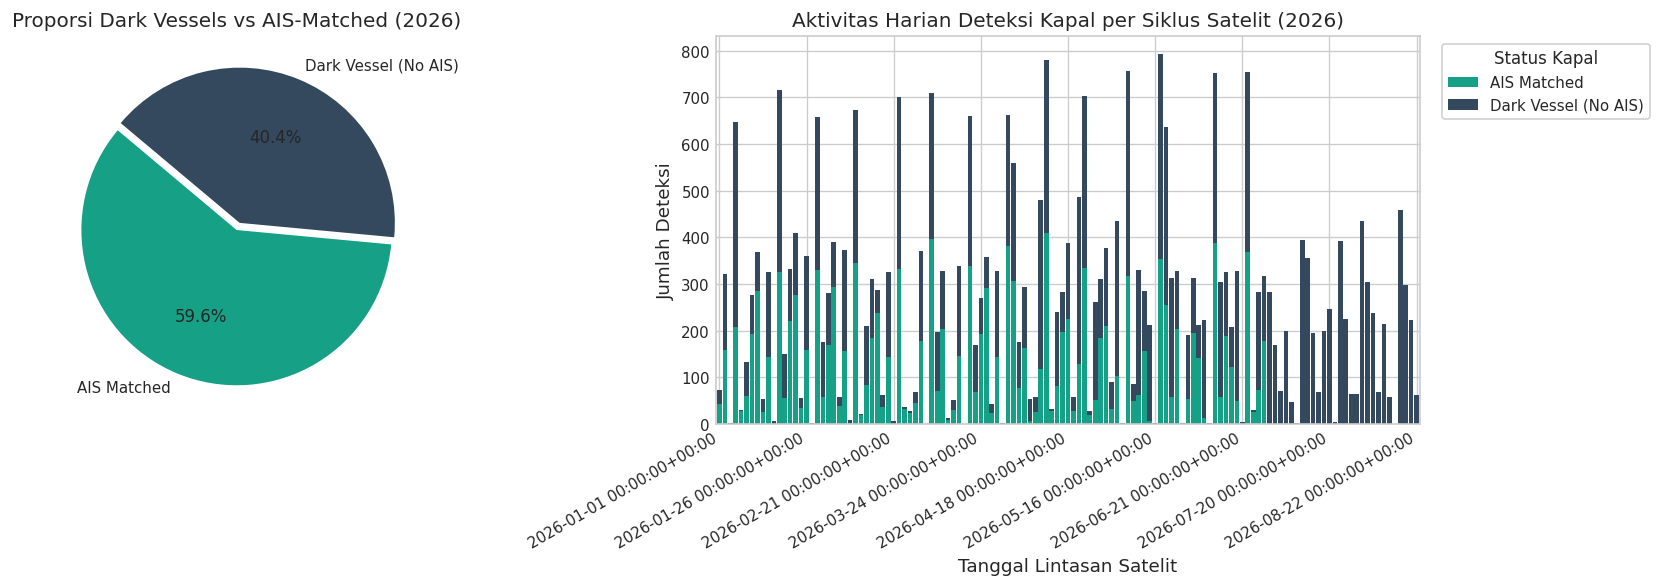

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
dark_counts = df_natuna_2026['is_dark'].value_counts()
axes[0].pie(dark_counts, labels=['AIS Matched', 'Dark Vessel (No AIS)'], autopct='%1.1f%%',
            colors=[PALETTE['ais'], PALETTE['dark']], startangle=140, explode=(0, 0.05))
axes[0].set_title('Proporsi Dark Vessels vs AIS-Matched (2026)')

daily_summary = df_natuna_2026.groupby(['pass_date', 'is_dark']).size().unstack(fill_value=0)
for col_idx in [0, 1]:
    if col_idx not in daily_summary.columns:
        daily_summary[col_idx] = 0
daily_summary = daily_summary[[0, 1]].rename(columns={0: 'AIS Matched', 1: 'Dark Vessel (No AIS)'})

daily_summary.plot(kind='bar', stacked=True, ax=axes[1], color=[PALETTE['ais'], PALETTE['dark']], width=0.85)
axes[1].set_title('Aktivitas Harian Deteksi Kapal per Siklus Satelit (2026)')
axes[1].set_xlabel('Tanggal Lintasan Satelit')
axes[1].set_ylabel('Jumlah Deteksi')

n_dates = len(daily_summary)
step = max(1, n_dates // 8)
tick_positions = list(range(0, n_dates, step))
tick_labels = [str(daily_summary.index[i]) for i in tick_positions]
axes[1].set_xticks(tick_positions)
axes[1].set_xticklabels(tick_labels, rotation=30, ha='right')
axes[1].legend(title='Status Kapal', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()


# Phase 3: Spatio-Temporal Tracking & Machine Learning Estimates

Integrasi data historis (2023–2025) dengan data terbaru 2026:
1. **Klaster Spatio-Temporal (Moore Neighborhood 30 Hari)**: Persistensi keberadaan kapal gelap pada jendela 30 hari di 9 sel tetangga (`area_dark_count_30d`, `area_dark_flag`).
2. **Proksimitas Penangkapan IUU Historis**: Jarak minimum ke koordinat insiden penangkapan kapal sebelumnya (`dist_to_nearest_seizure_km`).
3. **Model Estimasi Panjang Kapal (`model_length_gb.pkl`)**: Model Gradient Boosting terlatih untuk estimasi ukuran kapal dari reflektivitas radar.
4. **Model Estimasi Fishing Score (`model_fishing_score_xgboost.pkl`)**: Model XGBoost terlatih dengan parameter oseanografi (Batimetri, SST, Arus Laut, Klorofil-a) untuk prediksi aktivitas penangkapan ikan.

In [ ]:
import os
import pandas as pd
import numpy as np
import gdown

NEW_DATA_ID = "1UO5VX9B4Rps4MwjEOpseNQZ-xuMAZ-wv"
NEW_DATA_PATH = "POSEIDON_complete_with_estimates.csv"

SEIZURE_ID = "11nifviDBWXHzss3pdvZwmANNbFz2kSvi"
SEIZURE_PATH = "POSEIDON_WPP711_seizures_with_length.csv"

if not os.path.exists(NEW_DATA_PATH):
    gdown.download(id=NEW_DATA_ID, output=NEW_DATA_PATH, quiet=False)

if not os.path.exists(SEIZURE_PATH):
    gdown.download(id=SEIZURE_ID, output=SEIZURE_PATH, quiet=False)

for path, name in [(NEW_DATA_PATH, "SAR + Estimasi"), (SEIZURE_PATH, "Seizure Historis")]:
    if os.path.exists(path):
        print(f"{name}: {path} ({os.path.getsize(path)/1024:.1f} KB)")
    else:
        print(f"{name} GAGAL terdownload: {path}")

sar = pd.read_csv(NEW_DATA_PATH, low_memory=False)
seiz = pd.read_csv(SEIZURE_PATH)

sar["timestamp"] = pd.to_datetime(sar["timestamp"], utc=True)
seiz["date"] = pd.to_datetime(seiz["date"], utc=True)

if "row_id" not in sar.columns:
    sar = sar.reset_index().rename(columns={"index": "row_id"})

print(f"\nTotal deteksi SAR termuat: {len(sar):,} baris")
print(f"Total Seizure Events termuat dari CSV: {len(seiz)}")

df_2026 = df_natuna_2026.copy() if 'df_natuna_2026' in locals() else pd.read_csv('POSEIDON_WPP711_complete_2026.csv')
print(f"Data 2026 dimuat: {len(df_2026):,} baris")

Downloading...
From: https://drive.google.com/uc?id=1UO5VX9B4Rps4MwjEOpseNQZ-xuMAZ-wv
To: /content/POSEIDON_complete_with_estimates.csv
100%|██████████| 77.4M/77.4M [00:00<00:00, 234MB/s]
Downloading...
From: https://drive.google.com/uc?id=11nifviDBWXHzss3pdvZwmANNbFz2kSvi
To: /content/POSEIDON_WPP711_seizures_with_length.csv
100%|██████████| 13.4k/13.4k [00:00<00:00, 24.9MB/s]


SAR + Estimasi: POSEIDON_complete_with_estimates.csv (75545.7 KB)
Seizure Historis: POSEIDON_WPP711_seizures_with_length.csv (13.0 KB)

Total deteksi SAR termuat: 151,851 baris
Total Seizure Events termuat dari CSV: 61
Data 2026 dimuat: 32,897 baris


### Fungsi Jarak ke Titik Penangkapan IUU (Haversine Distance)

In [ ]:
seiz['date'] = pd.to_datetime(seiz['date'])
seiz['year'] = seiz['date'].dt.year

BBOX_LON_MIN, BBOX_LON_MAX = 102.90, 111.05
BBOX_LAT_MIN, BBOX_LAT_MAX = -4.16, 7.74

di_luar_bbox = ~(
    seiz['lon'].between(BBOX_LON_MIN, BBOX_LON_MAX) &
    seiz['lat'].between(BBOX_LAT_MIN, BBOX_LAT_MAX)
)

print(f"Total baris seizure         : {len(seiz)}")
print(f"Di luar bounding box WPP-711: {di_luar_bbox.sum()}")
print(f"Di dalam bounding box WPP-711: {(~di_luar_bbox).sum()}")

if di_luar_bbox.sum() > 0:
    print("\nBaris yang di luar bbox:")
    display(seiz[di_luar_bbox][['date', 'lat', 'lon', 'vessel_flag']])

seiz_dated = seiz.copy()
seiz_dated['year'] = seiz_dated['date'].dt.year

in_bbox = (
    seiz_dated['lon'].between(BBOX_LON_MIN, BBOX_LON_MAX) &
    seiz_dated['lat'].between(BBOX_LAT_MIN, BBOX_LAT_MAX)
)

df_seizures_ref = seiz_dated[in_bbox & (seiz_dated['year'] <= 2025)].copy()

print(f"\nTotal titik referensi seizure (WPP-711 saja, tahun <=2025): {len(df_seizures_ref)}")

seiz_lat = df_seizures_ref['lat'].values
seiz_lon = df_seizures_ref['lon'].values

def compute_dist_to_seizure(lat_arr, lon_arr, seiz_lat, seiz_lon):
    lat_r = np.radians(lat_arr)[:, None]
    lon_r = np.radians(lon_arr)[:, None]
    seiz_lat_r = np.radians(seiz_lat)[None, :]
    seiz_lon_r = np.radians(seiz_lon)[None, :]

    dlat = seiz_lat_r - lat_r
    dlon = seiz_lon_r - lon_r
    a = np.sin(dlat/2)**2 + np.cos(lat_r)*np.cos(seiz_lat_r)*np.sin(dlon/2)**2
    dists_matrix = 2 * 6371.0088 * np.arcsin(np.sqrt(a))

    dists_sorted = np.sort(dists_matrix, axis=1)
    min_dists = np.where(
        dists_sorted[:, 0] < 0.05,
        np.where(dists_sorted.shape[1] > 1, dists_sorted[:, 1], -1.0),
        dists_sorted[:, 0]
    )
    return np.round(min_dists, 4)

dist_lama = sar['dist_to_nearest_seizure_km'].copy() if 'dist_to_nearest_seizure_km' in sar.columns else pd.Series([np.nan]*len(sar))
sar['dist_to_nearest_seizure_km'] = compute_dist_to_seizure(sar['lat'].values, sar['lon'].values, seiz_lat, seiz_lon)
n_berubah = (dist_lama != sar['dist_to_nearest_seizure_km']).sum()
print(f"Histori: {n_berubah} dari {len(sar)} baris berubah nilainya")

df_2026['dist_to_nearest_seizure_km'] = compute_dist_to_seizure(df_2026['lat'].values, df_2026['lon'].values, seiz_lat, seiz_lon)
print(f"2026: dist_to_nearest_seizure_km selesai dihitung untuk {len(df_2026)} baris")


Total baris seizure         : 61
Di luar bounding box WPP-711: 5
Di dalam bounding box WPP-711: 56

Baris yang di luar bbox:


,date,lat,lon,vessel_flag
35,2024-03-07 00:00:00+00:00,-3.379233,122.963983,Indonesia
55,2025-05-20 00:00:00+00:00,-5.679800,105.667117,Vietnam
56,2025-05-20 00:00:00+00:00,-5.666833,105.723050,Vietnam
58,2025-07-29 00:00:00+00:00,3.170517,100.633350,Malaysia
59,2025-08-12 00:00:00+00:00,-0.981333,100.157550,Indonesia



Total titik referensi seizure (WPP-711 saja, tahun <=2025): 56
Histori: 150300 dari 151851 baris berubah nilainya
2026: dist_to_nearest_seizure_km selesai dihitung untuk 32897 baris


### Standardisasi Grid Spasial ($0.1^\circ \times 0.1^\circ$) & Indexing

In [ ]:
df_2026['grid_lat'] = np.floor(df_2026['lat'] / 0.1).astype(int)
df_2026['grid_lon'] = np.floor(df_2026['lon'] / 0.1).astype(int)
df_2026['pass_date'] = df_2026['timestamp'].dt.floor('D')
df_2026['is_dark'] = (df_2026['matched_category'] == 'unmatched').astype(int)

sar['pass_date'] = sar['timestamp'].dt.floor('D')
if 'grid_lat' not in sar.columns:
    sar['grid_lat'] = np.floor(sar['lat'] / 0.1).astype(int)
    sar['grid_lon'] = np.floor(sar['lon'] / 0.1).astype(int)
if 'is_dark' not in sar.columns:
    sar['is_dark'] = (sar['matched_category'] == 'unmatched').astype(int)

common_cols = ['scene_id', 'timestamp', 'lat', 'lon', 'matched_category',
                'length_m', 'vv_intensity_db', 'vh_intensity_db',
                'grid_lat', 'grid_lon', 'pass_date', 'is_dark']
common_cols = [c for c in common_cols if c in sar.columns and c in df_2026.columns]

df_combined = pd.concat([sar[common_cols], df_2026[common_cols]], ignore_index=True)
df_combined = df_combined.sort_values('timestamp').reset_index(drop=True)
df_combined['is_2026'] = df_combined['timestamp'].dt.year == 2026
idx_2026 = df_combined.index[df_combined['is_2026']].to_numpy()

print(f"Total baris gabungan: {len(df_combined)}")
print(f"Baris 2026 yang perlu dihitung Dimensi D: {len(idx_2026)}")


Total baris gabungan: 184748
Baris 2026 yang perlu dihitung Dimensi D: 32897


### Algoritma Moore Neighborhood 9-Cell Spatio-Temporal 30 Hari

In [ ]:
import time

sorted_pass_dates = sorted(df_combined['pass_date'].unique())
prev_pass_date_map = {d: (sorted_pass_dates[i-1] if i > 0 else None) for i, d in enumerate(sorted_pass_dates)}

MOORE_OFFSETS_9 = [(dlat, dlon) for dlat in (-1, 0, 1) for dlon in (-1, 0, 1)]
MOORE_OFFSETS_8 = [o for o in MOORE_OFFSETS_9 if o != (0, 0)]

dark_df = df_combined[df_combined['is_dark'] == 1]
dark_unique_scene = dark_df.drop_duplicates(subset=['grid_lat','grid_lon','scene_id'])[['grid_lat','grid_lon','scene_id','pass_date']]

grid_dark_scene_index = {}
for key, g in dark_unique_scene.groupby(['grid_lat', 'grid_lon']):
    g_sorted = g.sort_values('pass_date')
    grid_dark_scene_index[key] = (g_sorted['pass_date'].to_numpy(), g_sorted['scene_id'].to_numpy())

dark_grid_date_counts = dark_df.groupby(['pass_date', 'grid_lat', 'grid_lon']).size().to_dict()

candidate_lookup = {}
for key, g in df_combined.groupby(['pass_date', 'grid_lat', 'grid_lon']):
    candidate_lookup[key] = g[['length_m', 'vv_intensity_db', 'vh_intensity_db']].to_numpy()

print("Index lookup dari data gabungan (2023-2026) selesai dibangun.")

grid_lat_arr = df_combined['grid_lat'].to_numpy()
grid_lon_arr = df_combined['grid_lon'].to_numpy()
pass_date_arr = df_combined['pass_date'].to_numpy()
window_30d = np.timedelta64(30, 'D')

length_arr = df_combined['length_m'].to_numpy()
vv_arr = df_combined['vv_intensity_db'].to_numpy()
vh_arr = df_combined['vh_intensity_db'].to_numpy()
LENGTH_TOLERANCE, DB_TOLERANCE = 0.15, 3.0

area_dark_count_30d = np.zeros(len(idx_2026), dtype=int)
neighbor_dark_prev = np.zeros(len(idx_2026), dtype=int)
vessel_redetection = np.zeros(len(idx_2026), dtype=int)

t_start = time.time()
for j, i in enumerate(idx_2026):
    glat, glon, current_date = grid_lat_arr[i], grid_lon_arr[i], pass_date_arr[i]

    window_start = current_date - window_30d
    scenes_in_window = set()
    for dlat, dlon in MOORE_OFFSETS_9:
        idxx = grid_dark_scene_index.get((glat+dlat, glon+dlon))
        if idxx is None: continue
        dates_arr, scenes_arr = idxx
        lo = np.searchsorted(dates_arr, window_start, side='left')
        hi = np.searchsorted(dates_arr, current_date, side='left')
        if hi > lo:
            scenes_in_window.update(scenes_arr[lo:hi])
    area_dark_count_30d[j] = len(scenes_in_window)

    prev_date = prev_pass_date_map.get(current_date)
    if prev_date is not None:
        total = 0
        for dlat, dlon in MOORE_OFFSETS_8:
            total += dark_grid_date_counts.get((prev_date, glat+dlat, glon+dlon), 0)
        neighbor_dark_prev[j] = total

        L = length_arr[i]
        if L > 0:
            candidate_arrays = []
            for dlat, dlon in MOORE_OFFSETS_9:
                cand = candidate_lookup.get((prev_date, glat+dlat, glon+dlon))
                if cand is not None and len(cand):
                    candidate_arrays.append(cand)
            if candidate_arrays:
                candidates = np.vstack(candidate_arrays)
                length_match = np.abs(candidates[:,0] - L) / L <= LENGTH_TOLERANCE
                vv_match = np.abs(candidates[:,1] - vv_arr[i]) <= DB_TOLERANCE
                vh_match = np.abs(candidates[:,2] - vh_arr[i]) <= DB_TOLERANCE
                if np.any(length_match & vv_match & vh_match):
                    vessel_redetection[j] = 1

    if (j+1) % 5000 == 0:
        print(f"  progres: {j+1}/{len(idx_2026)}")

df_2026['area_dark_count_30d'] = area_dark_count_30d
df_2026['area_dark_flag'] = (df_2026['area_dark_count_30d'] >= 2).astype(int)
df_2026['neighbor_dark_prev'] = neighbor_dark_prev
df_2026['vessel_redetection'] = vessel_redetection

print(f"\nSelesai dalam {time.time()-t_start:.1f} detik")

Index lookup dari data gabungan (2023-2026) selesai dibangun.
  progres: 5000/32897
  progres: 10000/32897
  progres: 15000/32897
  progres: 20000/32897
  progres: 25000/32897
  progres: 30000/32897

Selesai dalam 8.7 detik


### Identifikasi Grid Hotspot IUU Historis

In [ ]:
hotspot_grids = set(
    sar.loc[sar['historical_hotspot'] == 1, ['grid_lat','grid_lon']]
    .drop_duplicates().apply(tuple, axis=1)
) if 'historical_hotspot' in sar.columns else set()
print(f"Jumlah grid hotspot (dari histori): {len(hotspot_grids)}")

df_2026['historical_hotspot'] = df_2026.apply(
    lambda r: 1 if (r['grid_lat'], r['grid_lon']) in hotspot_grids else 0, axis=1
)
print(df_2026['historical_hotspot'].value_counts())

Jumlah grid hotspot (dari histori): 850
historical_hotspot
1    20256
0    12641
Name: count, dtype: int64


### Pembersihan Kategori Kapal Anomali (Noisy / Discrepancy)

In [ ]:
drop_cats = ['noisy_vessel', 'discrepancy']
df_2026_clean = df_2026[~df_2026['matched_category'].isin(drop_cats)].copy()
df_2026_clean['matched_category'] = df_2026_clean['matched_category'].replace('seismic_vessel', 'seismicvessel')

print(f"Baris sebelum filter: {len(df_2026)}, sesudah: {len(df_2026_clean)}")

Baris sebelum filter: 32897, sesudah: 32398


### Pemuatan Model Gradient Boosting Estimasi Panjang Kapal

In [ ]:
import joblib
import gdown

MODEL_LEN_ID = '1IPKwME5f-TgfqE5V3f99JAwKmi4y1e8R'
model_len_path = 'model_length_gb.pkl'

if not os.path.exists(model_len_path):
    gdown.download(id=MODEL_LEN_ID, output=model_len_path, quiet=False)

best_model_length = joblib.load(model_len_path)

feature_cols_length = ['vv_intensity_db', 'vh_intensity_db', 'vv_vh_ratio',
                        'radar_intensity_diff', 'snr_db', 'background_clutter']

df_2026_clean['radar_intensity_diff'] = df_2026_clean['vv_intensity_db'] - df_2026_clean['vh_intensity_db']

missing_check = df_2026_clean[feature_cols_length].isnull().sum()
print("Missing value per fitur:")
print(missing_check)

df_2026_clean['length_m_new'] = best_model_length.predict(df_2026_clean[feature_cols_length])
if 'length_m' in df_2026_clean.columns:
    print(f"\nKorelasi length_m vs length_m_new: {df_2026_clean['length_m'].corr(df_2026_clean['length_m_new']):.4f}")

Downloading...
From: https://drive.google.com/uc?id=1IPKwME5f-TgfqE5V3f99JAwKmi4y1e8R
To: /content/model_length_gb.pkl
100%|██████████| 398k/398k [00:00<00:00, 78.7MB/s]


Missing value per fitur:
vv_intensity_db         0
vh_intensity_db         0
vv_vh_ratio             0
radar_intensity_diff    0
snr_db                  0
background_clutter      0
dtype: int64

Korelasi length_m vs length_m_new: 0.8985


### Integrasi Parameter Oseanografi WPP 711 (Batimetri, SST, Arus, Klorofil-a)

In [ ]:
import gdown

file_id = '1yreRiRL8w0cJ8NYAZTDs2ILa61dJFhrX'
grid_env_path = 'wpp711_grid_environmental_full.csv'
if not os.path.exists(grid_env_path):
    url = f'https://drive.google.com/uc?id={file_id}'
    gdown.download(url, grid_env_path, quiet=False)

grid_env = pd.read_csv(grid_env_path)
env_cols = ['grid_lat', 'grid_lon', 'bathymetry', 'sst_mean', 'sst_std',
            'current_speed_mean', 'current_speed_std', 'chlorophyll_mean']
env_cols = [c for c in env_cols if c in grid_env.columns]

df_2026_clean = df_2026_clean.merge(grid_env[env_cols], on=['grid_lat', 'grid_lon'], how='left')
print("Missing setelah join oseanografi:")
print(df_2026_clean[[c for c in env_cols if c not in ('grid_lat', 'grid_lon')]].isnull().sum())

Downloading...
From: https://drive.google.com/uc?id=1yreRiRL8w0cJ8NYAZTDs2ILa61dJFhrX
To: /content/wpp711_grid_environmental_full.csv
100%|██████████| 892k/892k [00:00<00:00, 106MB/s]

Missing setelah join oseanografi:
bathymetry            0
sst_mean              0
sst_std               0
current_speed_mean    0
current_speed_std     0
chlorophyll_mean      0
dtype: int64


### Pemuatan Model XGBoost Estimasi Fishing Score

In [ ]:
import joblib
import gdown

MODEL_FISH_ID = '1JfJ7ww1f-zRoCF1kezwSTy7e4_1szsxy'
model_fish_path = 'model_fishing_score_xgboost.pkl'

if not os.path.exists(model_fish_path):
    gdown.download(id=MODEL_FISH_ID, output=model_fish_path, quiet=False)

best_model_fishing = joblib.load(model_fish_path)

feature_cols_fishing = [
    'length_m_new', 'vv_intensity_db', 'vh_intensity_db', 'vv_vh_ratio',
    'bathymetry', 'sst_mean', 'sst_std', 'current_speed_mean',
    'current_speed_std', 'chlorophyll_mean', 'dist_to_nearest_port_km',
]

df_2026_clean['fishing_score_new'] = best_model_fishing.predict(df_2026_clean[feature_cols_fishing])
df_2026_clean['fishing_score_new'] = np.clip(df_2026_clean['fishing_score_new'], 0, 1)

if 'fishing_score' in df_2026_clean.columns:
    print(df_2026_clean[['fishing_score', 'fishing_score_new']].describe())

Downloading...
From: https://drive.google.com/uc?id=1JfJ7ww1f-zRoCF1kezwSTy7e4_1szsxy
To: /content/model_fishing_score_xgboost.pkl
100%|██████████| 1.41M/1.41M [00:00<00:00, 146MB/s]


       fishing_score  fishing_score_new
count   27050.000000       32398.000000
mean        0.275730           0.262493
std         0.315646           0.260716
min         0.012883           0.000000
25%         0.012883           0.047534
50%         0.094884           0.161565
75%         0.550905           0.420889
max         0.960768           1.000000


### Sinkronisasi ID Baris Kontinu (Row ID) & Penyimpanan Dataset 2026

In [ ]:
output_path = 'POSEIDON_2026_complete_with_estimates.csv'
df_2026_clean.to_csv(output_path, index=False)
print(f"Tersimpan: {output_path}")
print(f"Baris: {len(df_2026_clean)}, Kolom: {len(df_2026_clean.columns)}")

sar_output_path = 'POSEIDON_complete_with_estimates_v2.csv'
sar.to_csv(sar_output_path, index=False)
print(f"Histori (dengan dist_to_nearest_seizure_km terbaru) tersimpan: {sar_output_path}")

cols_hist = set(sar.columns)
cols_2026 = set(df_2026_clean.columns)

print("Kolom cuma ada di histori:", cols_hist - cols_2026)
print("Kolom cuma ada di 2026   :", cols_2026 - cols_hist)

max_row_id_hist = sar['row_id'].max()
print(f"row_id tertinggi di histori: {max_row_id_hist}")

df_2026_clean = df_2026_clean.reset_index(drop=True)
df_2026_clean['row_id'] = df_2026_clean.index + max_row_id_hist + 1

print(f"row_id 2026 dimulai dari: {df_2026_clean['row_id'].min()} sampai {df_2026_clean['row_id'].max()}")
cols_hist = set(sar.columns)
cols_2026 = set(df_2026_clean.columns)
print("\nKolom cuma ada di histori:", cols_hist - cols_2026)
print("Kolom cuma ada di 2026   :", cols_2026 - cols_hist)

combined_check = pd.concat([sar['row_id'], df_2026_clean['row_id']])
print(f"\nTotal baris gabungan: {len(combined_check)}")
print(f"Total row_id unik   : {combined_check.nunique()}")
print("Aman (tidak ada duplikat):", len(combined_check) == combined_check.nunique())

Tersimpan: POSEIDON_2026_complete_with_estimates.csv
Baris: 32398, Kolom: 50
Histori (dengan dist_to_nearest_seizure_km terbaru) tersimpan: POSEIDON_complete_with_estimates_v2.csv
Kolom cuma ada di histori: {'row_id'}
Kolom cuma ada di 2026   : {'day_of_week', 'quarter'}
row_id tertinggi di histori: 151850
row_id 2026 dimulai dari: 151851 sampai 184248

Kolom cuma ada di histori: set()
Kolom cuma ada di 2026   : {'day_of_week', 'quarter'}

Total baris gabungan: 184249
Total row_id unik   : 184249
Aman (tidak ada duplikat): True


### Visualisasi Korelasi Estimasi Fitur & Densitas Spasial Dark Vessel

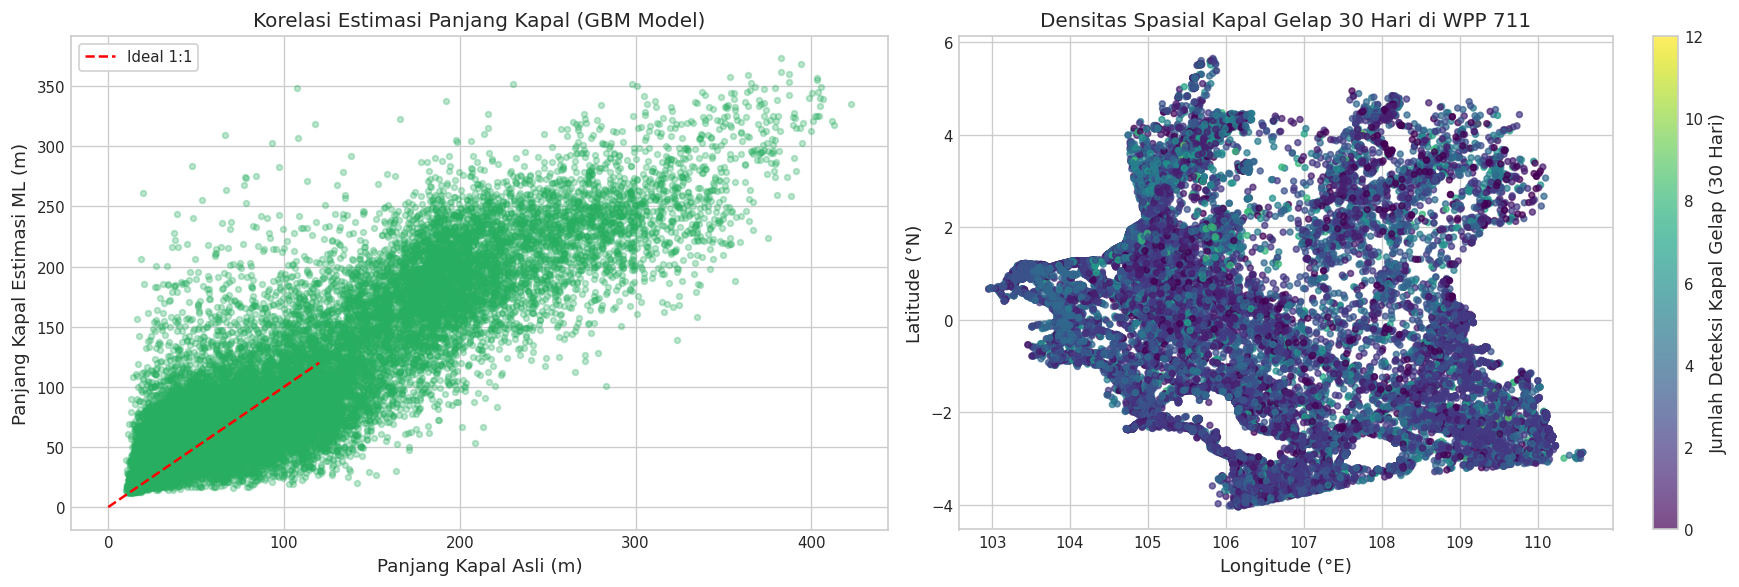

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
orig_len = df_2026_clean['length_m'] if 'length_m' in df_2026_clean.columns else df_2026_clean['length_m_new']
axes[0].scatter(orig_len, df_2026_clean['length_m_new'], alpha=0.3, color=PALETTE['new'], s=12)
axes[0].plot([0, 120], [0, 120], 'r--', label='Ideal 1:1')
axes[0].set_xlabel('Panjang Kapal Asli (m)')
axes[0].set_ylabel('Panjang Kapal Estimasi ML (m)')
axes[0].set_title('Korelasi Estimasi Panjang Kapal (GBM Model)')
axes[0].legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

sc = axes[1].scatter(df_2026_clean['lon'], df_2026_clean['lat'], c=df_2026_clean['area_dark_count_30d'], cmap='viridis', s=12, alpha=0.7)
plt.colorbar(sc, ax=axes[1], label='Jumlah Deteksi Kapal Gelap (30 Hari)')
axes[1].set_xlabel('Longitude (°E)')
axes[1].set_ylabel('Latitude (°N)')
axes[1].set_title('Densitas Spasial Kapal Gelap 30 Hari di WPP 711')
plt.tight_layout()
plt.show()

# Label Engineering (2023-2025)

Pemberian label ground truth (P / RN / U) pada deteksi radar SAR Sentinel-1 berdasarkan data penangkapan kapal (*seizure events*) Bakamla/KKP/TNI-AL.

## 1.1 Fungsi Haversine Distance

In [ ]:
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0088
    lat1r, lon1r, lat2r, lon2r = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2r - lat1r
    dlon = lon2r - lon1r
    a = np.sin(dlat/2)**2 + np.cos(lat1r)*np.cos(lat2r)*np.sin(dlon/2)**2
    return 2*R*np.arcsin(np.sqrt(a))

BBOX_LON_MIN, BBOX_LON_MAX = 102.90, 111.05
BBOX_LAT_MIN, BBOX_LAT_MAX = -4.16, 7.74
TIME_WINDOW_MIN = pd.Timedelta(days=12)
TIME_WINDOW_MAX = pd.Timedelta(days=1)
SPATIAL_RADIUS_KM = 30.0
rn_vessel_types = ['cargo', 'bunker', 'carrier', 'passenger']

## 1.2 Matching Seizure Events ke Deteksi SAR (Label P)

In [ ]:
def run_matching(sar_df, seiz_df):
    sar_in_bbox = sar_df['lon'].between(BBOX_LON_MIN, BBOX_LON_MAX) & sar_df['lat'].between(BBOX_LAT_MIN, BBOX_LAT_MAX)
    sar_clean = sar_df[sar_in_bbox].copy().reset_index(drop=True)

    seiz_in_bbox = seiz_df['lon'].between(BBOX_LON_MIN, BBOX_LON_MAX) & seiz_df['lat'].between(BBOX_LAT_MIN, BBOX_LAT_MAX)
    seiz_clean = seiz_df[seiz_in_bbox].copy()

    seizure_candidates = {}
    for idx_seiz, row_seiz in seiz_clean.iterrows():
        s_date, s_lat, s_lon = row_seiz['date'], row_seiz['lat'], row_seiz['lon']
        s_flag = str(row_seiz['vessel_flag'])
        s_length = row_seiz['length']

        min_time = s_date - TIME_WINDOW_MIN
        max_time = s_date + TIME_WINDOW_MAX
        time_mask = (sar_clean['timestamp'] >= min_time) & (sar_clean['timestamp'] <= max_time)
        candidates = sar_clean[time_mask].copy()
        if len(candidates) == 0:
            continue

        dists = haversine_km(candidates['lat'].values, candidates['lon'].values, s_lat, s_lon)
        candidates['dist_km'] = dists
        candidates = candidates[candidates['dist_km'] <= SPATIAL_RADIUS_KM]
        if len(candidates) == 0:
            continue

        if s_flag.lower() != 'indonesia':
            candidates = candidates[candidates['ais_matched'] == 0]
            if len(candidates) == 0:
                continue

        candidates['time_diff_days'] = (candidates['timestamp'] - s_date).abs().dt.total_seconds() / 86400.0
        norm_dist = candidates['dist_km'] / SPATIAL_RADIUS_KM
        norm_time = candidates['time_diff_days'] / 12.0
        candidates['st_score'] = 0.5 * norm_dist + 0.5 * norm_time

        candidates = candidates.sort_values(by='st_score').head(20).copy()
        candidates['st_rank'] = range(1, len(candidates) + 1)
        candidates['length_diff'] = (candidates['length_m'] - s_length).abs()

        valid_candidates = candidates[candidates['length_diff'] <= 30.0].copy()
        if len(valid_candidates) == 0:
            continue

        valid_candidates = valid_candidates.sort_values(
            by=['length_diff', 'st_rank', 'fishing_score'],
            ascending=[True, True, False]
        )
        valid_candidates['st_rank'] = range(1, len(valid_candidates) + 1)
        seizure_candidates[idx_seiz] = valid_candidates

    assigned_sar_to_seiz = {}
    seiz_final_match = {}
    unassigned_seizures = set(seizure_candidates.keys())

    while unassigned_seizures:
        progress = False
        for s_idx in list(unassigned_seizures):
            cand_df = seizure_candidates[s_idx]
            for idx_cand, c_row in cand_df.iterrows():
                sar_idx = idx_cand
                c_len_diff = c_row['length_diff']
                c_st_rank = c_row['st_rank']

                if sar_idx not in assigned_sar_to_seiz:
                    assigned_sar_to_seiz[sar_idx] = (s_idx, c_len_diff, c_st_rank)
                    seiz_final_match[s_idx] = sar_idx
                    unassigned_seizures.remove(s_idx)
                    progress = True
                    break
                else:
                    ex_s_idx, ex_len_diff, ex_st_rank = assigned_sar_to_seiz[sar_idx]
                    is_better = (c_len_diff < ex_len_diff - 1e-4) or (abs(c_len_diff - ex_len_diff) <= 1e-4 and c_st_rank < ex_st_rank)
                    if is_better:
                        assigned_sar_to_seiz[sar_idx] = (s_idx, c_len_diff, c_st_rank)
                        seiz_final_match[s_idx] = sar_idx
                        unassigned_seizures.remove(s_idx)
                        if ex_s_idx in seiz_final_match and seiz_final_match[ex_s_idx] == sar_idx:
                            del seiz_final_match[ex_s_idx]
                        unassigned_seizures.add(ex_s_idx)
                        progress = True
                        break
        if not progress:
            break

    p_audit_list = []
    for s_idx, sar_idx in sorted(seiz_final_match.items()):
        c_df = seizure_candidates[s_idx]
        best_row = c_df.loc[sar_idx]
        f_score = float(best_row['fishing_score'])
        len_diff = float(best_row['length_diff'])
        is_anomaly = (f_score < 0.3) or (len_diff > 30.0)
        p_audit_list.append({'sar_idx': sar_idx, 'is_anomaly': is_anomaly})

    df_audit = pd.DataFrame(p_audit_list)
    strict_p_indices = set(df_audit.loc[~df_audit['is_anomaly'], 'sar_idx']) if len(df_audit) else set()
    rawan_indices = set(df_audit.loc[df_audit['is_anomaly'], 'sar_idx']) if len(df_audit) else set()

    sar_labeled = sar_clean.copy()
    sar_labeled['label'] = 'U'
    sar_labeled.loc[list(strict_p_indices), 'label'] = 'P'
    print("Proses Labeling Selesai")
    return sar_labeled

## 1.3 Pelabelan Reliable Negative (Label RN)



In [ ]:
def apply_rn_label(df):
    rn_mask = (
        (df['ais_matched'] == 1) &
        (df['fishing_score'] < 0.1) &
        (df['ais_vessel_type'].isin(rn_vessel_types)) &
        (df['label'] != 'P')
    )
    df.loc[rn_mask, 'label'] = 'RN'
    return df

print("Fungsi pelabelan Reliable Negative (Label RN) terdefinisi.")

Fungsi pelabelan Reliable Negative (Label RN) terdefinisi.


## 1.4 Evaluasi Pasca Matching & Pelabelan Historis (2023-2025)

In [ ]:
if 'row_id' not in sar.columns:
    sar = sar.reset_index().rename(columns={'index': 'row_id'})

sar_labeled_2023_2025 = run_matching(sar, seiz)

n_p = (sar_labeled_2023_2025['label'] == 'P').sum()
print(f"\nVerifikasi: jumlah P = {n_p}")
assert n_p == 36, f"MISMATCH! Dapat {n_p}"

Proses Labeling Selesai

Verifikasi: jumlah P = 36


## 1.5 Penerapan Filter Strict & Pembersihan Label P Akhir

In [ ]:
p_rows = sar_labeled_2023_2025[sar_labeled_2023_2025['label'] == 'P']
print(f"Total deteksi SAR terlabeli P pada data historis: {len(p_rows):,}")
cols_p = [c for c in ['row_id', 'timestamp', 'lat', 'lon', 'length_m', 'fishing_score'] if c in p_rows.columns]
print(p_rows[cols_p].head())

Total deteksi SAR terlabeli P pada data historis: 36
       row_id                 timestamp       lat         lon   length_m  \
11380   11380 2023-03-11 11:17:49+00:00  2.656505  105.026875  17.606619   
11610   11610 2023-03-11 11:18:14+00:00  2.802915  104.978763  18.225983   
12340   12340 2023-03-17 22:48:00+00:00  3.031712  104.953084  22.131084   
12995   12995 2023-03-19 22:33:30+00:00 -3.336744  106.504814  22.417774   
13038   13038 2023-03-19 22:33:30+00:00 -3.486035  106.717079  23.696207   

       fishing_score  
11380       0.960768  
11610       0.960768  
12340       0.960768  
12995       0.623242  
13038       0.505672  


## 1.6 Exploratory Data Analysis (Pipeline GFW)

### Distribusi Spasial Deteksi SAR dan Lokasi Penangkapan (Pipeline GFW)

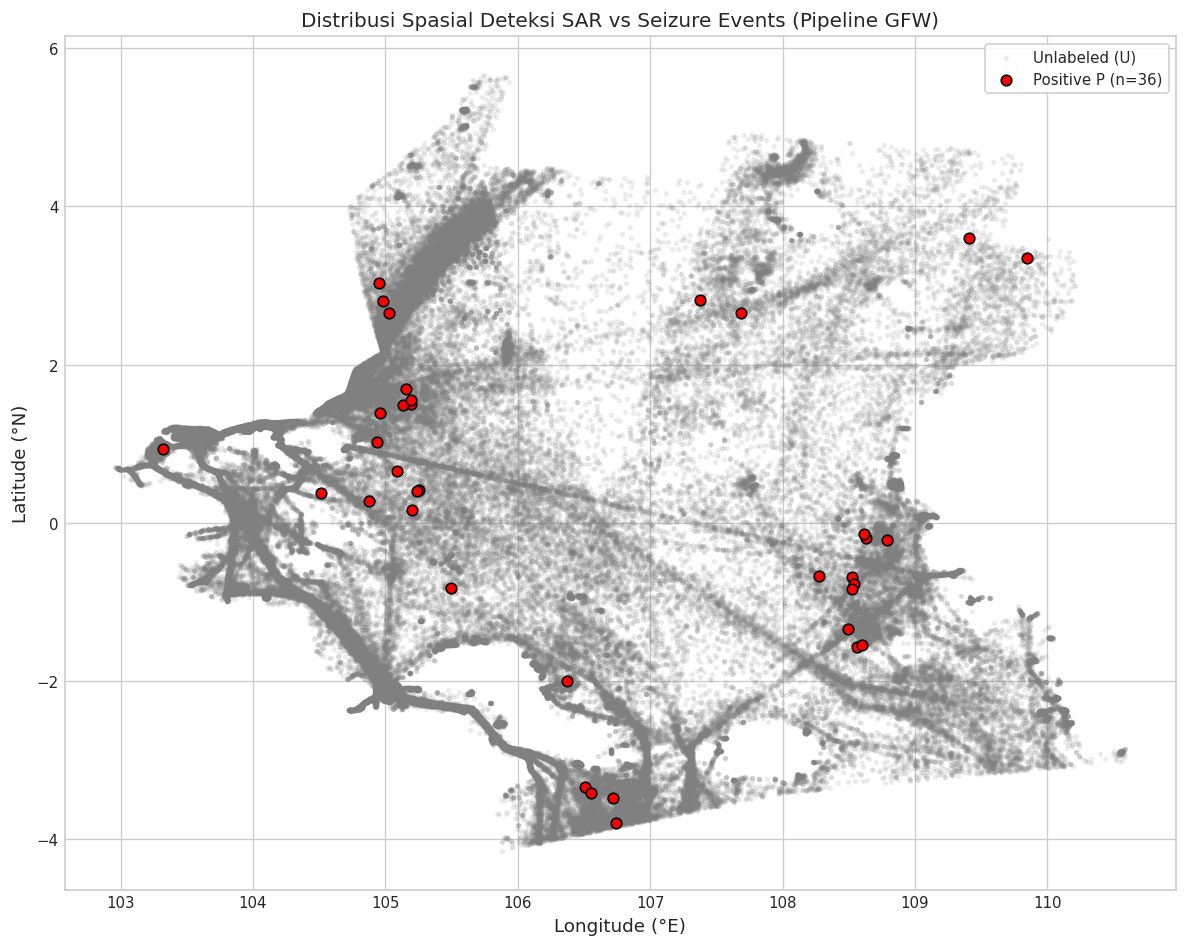

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))
u_data = sar_labeled_2023_2025[sar_labeled_2023_2025['label'] == 'U']
p_data = sar_labeled_2023_2025[sar_labeled_2023_2025['label'] == 'P']
ax.scatter(u_data['lon'], u_data['lat'], c='gray', alpha=0.1, s=5, label='Unlabeled (U)')
ax.scatter(p_data['lon'], p_data['lat'], c='red', s=40, edgecolors='black', label=f'Positive P (n={len(p_data)})')
ax.set_xlabel('Longitude (°E)')
ax.set_ylabel('Latitude (°N)')
ax.set_title('Distribusi Spasial Deteksi SAR vs Seizure Events (Pipeline GFW)')
ax.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()

### Distribusi Panjang Kapal per Label (Pipeline GFW)

Uji KS Panjang Kapal (P vs U): Stat=0.7025, p-value=2.3416e-18


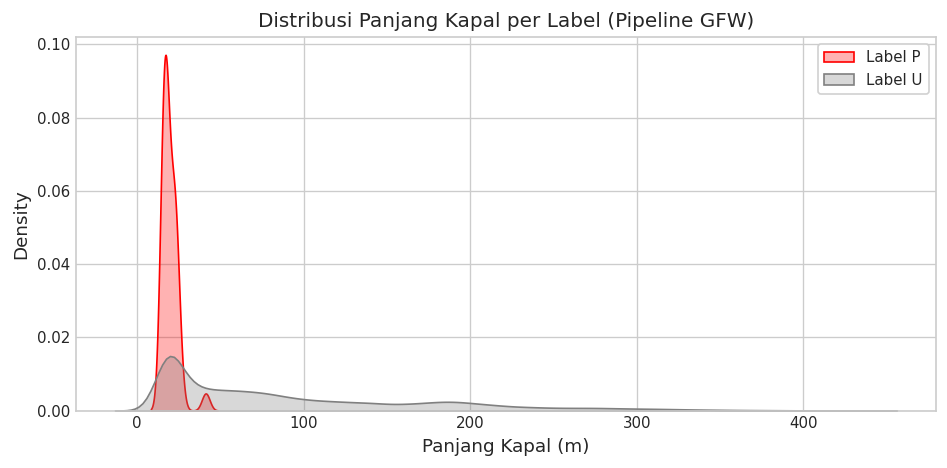

In [ ]:
p_len = sar_labeled_2023_2025.loc[sar_labeled_2023_2025['label'] == 'P', 'length_m'].dropna()
u_len = sar_labeled_2023_2025.loc[sar_labeled_2023_2025['label'] == 'U', 'length_m'].dropna()

ks_stat, ks_pval = ks_2samp(p_len, u_len)
print(f"Uji KS Panjang Kapal (P vs U): Stat={ks_stat:.4f}, p-value={ks_pval:.4e}")

fig, ax = plt.subplots(figsize=(8, 4))
sns.kdeplot(p_len, label='Label P', color='red', ax=ax, fill=True, alpha=0.3)
sns.kdeplot(u_len, label='Label U', color='gray', ax=ax, fill=True, alpha=0.3)
ax.set_xlabel('Panjang Kapal (m)')
ax.set_title('Distribusi Panjang Kapal per Label (Pipeline GFW)')
ax.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()

### Distribusi Fitur Radar dan Jarak per Label (Pipeline GFW)

In [ ]:
for col in ['vv_intensity_db', 'vh_intensity_db', 'dist_to_nearest_seizure_km']:
    if col in sar_labeled_2023_2025.columns:
        p_val = sar_labeled_2023_2025.loc[sar_labeled_2023_2025['label'] == 'P', col].dropna()
        u_val = sar_labeled_2023_2025.loc[sar_labeled_2023_2025['label'] == 'U', col].dropna()
        u_stat, p_val_mw = mannwhitneyu(p_val, u_val, alternative='two-sided')
        print(f"Mann-Whitney U {col}: Stat={u_stat:.2f}, p-value={p_val_mw:.4e}")

Mann-Whitney U vv_intensity_db: Stat=2095703.00, p-value=1.5432e-02
Mann-Whitney U vh_intensity_db: Stat=2160847.00, p-value=2.9678e-02
Mann-Whitney U dist_to_nearest_seizure_km: Stat=724757.50, p-value=2.2559e-14


### Distribusi Fishing Score: Dark Vessels vs AIS Matched (Pipeline GFW)

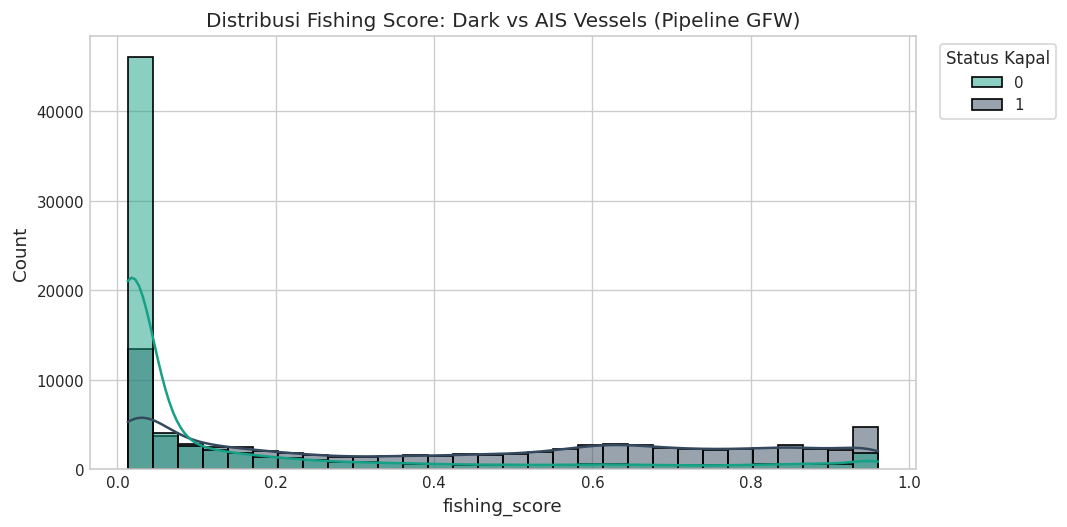

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(data=sar_labeled_2023_2025, x='fishing_score', hue='is_dark', kde=True, palette=[PALETTE['ais'], PALETTE['dark']], ax=ax, bins=30)
ax.set_title('Distribusi Fishing Score: Dark vs AIS Vessels (Pipeline GFW)')
try:
    sns.move_legend(ax, "upper left", bbox_to_anchor=(1.02, 1), title='Status Kapal', frameon=True)
except Exception:
    ax.legend(title='Status Kapal', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

# Label Engineering (di gabung dengan 2026)

menyatukan data deteksi berlabel 2023–2025 dengan data 2026 (gabungan GFW dan Fallback GEE) yang dicocokkan dengan data penangkapan resmi KKP 2026 (`Seizure_WPP711_2026_with_length_FIXED.csv`).

In [ ]:
file_id = "1K08sfv-Cht5GDCxFPlGbAH32zyjLRL_C"
seizure_2026_path = "Seizure_WPP711_2026_with_length_FIXED.csv"

if not os.path.exists(seizure_2026_path):
    gdown.download(id=file_id, output=seizure_2026_path, quiet=False)

seiz_2026 = pd.read_csv(seizure_2026_path)
seiz_2026['date'] = pd.to_datetime(seiz_2026['date'], utc=True)

if 'row_id' not in df_2026_clean.columns:
    max_row_id_hist = sar_labeled_2023_2025['row_id'].max()
    df_2026_clean = df_2026_clean.reset_index(drop=True)
    df_2026_clean['row_id'] = df_2026_clean.index + max_row_id_hist + 1

sar_labeled_2026 = run_matching(df_2026_clean, seiz_2026)

n_p_2026 = (sar_labeled_2026['label'] == 'P').sum()

sar_labeled_full = pd.concat([sar_labeled_2023_2025, sar_labeled_2026], ignore_index=True)
sar_labeled_full = apply_rn_label(sar_labeled_full)

sar_labeled = sar_labeled_full.copy()
sar_labeled_new = sar_labeled_full.copy()

sar_labeled_full['year'] = pd.to_datetime(sar_labeled_full['timestamp']).dt.year
sar_labeled_full.to_csv("POSEIDON_Full_Labeled.csv", index=False)

Downloading...
From: https://drive.google.com/uc?id=1K08sfv-Cht5GDCxFPlGbAH32zyjLRL_C
To: /content/Seizure_WPP711_2026_with_length_FIXED.csv
100%|██████████| 2.44k/2.44k [00:00<00:00, 6.72MB/s]


Proses Labeling Selesai
